# Agent Evaluation & Reliability Platform

**Executed offline notebook**. All sources are fictional and requests run the same `agent.py` code as the CLI and Streamlit app. The negative case deliberately injects a tool failure.

In [1]:
from pathlib import Path
import sys, json
from IPython.display import display, Image
BASE=Path.cwd()
sys.path.insert(0,str(BASE.parent))
from agent import run
CASES=json.loads((BASE/"data/eval_cases.json").read_text())
print("Dataset:",BASE.name,"| tasks:",len(CASES))

Dataset: 10-agent-evaluation-platform | tasks: 5


## Successful / approval-safe execution (actual local workflow)

In [2]:
case=next(c for c in CASES if c["id"]=='baseline')
success=run(case["request"],BASE,case.get("fault"))
print(json.dumps({"status":success["status"],"answer":success["answer"],"evidence":success["evidence"],"trace":success["trace"]},indent=2,ensure_ascii=False))
assert success["status"] == case["expected_status"]

{
  "status": "success",
  "answer": "Baseline success 75%; candidate success 75%. Archived synthetic traces; this run replays scoring, not external agents.",
  "evidence": [
    {
      "baseline": {
        "evaluated": 4,
        "task_success_rate": 0.75,
        "tool_failure_rate": 0.0833,
        "mean_latency_ms": 15.925,
        "model_api_cost_usd": 0,
        "details": [
          {
            "trace_id": "research-reliable",
            "success": true,
            "tool_failures": 0,
            "tool_calls": 3,
            "latency_ms": 22.4,
            "model_api_cost_usd": 0,
            "expected_status": "success"
          },
          {
            "trace_id": "sql-reliable",
            "success": true,
            "tool_failures": 0,
            "tool_calls": 2,
            "latency_ms": 11.8,
            "model_api_cost_usd": 0,
            "expected_status": "success"
          },
          {
            "trace_id": "billing-failed",
            "success": fa

## Failure case with a real injected tool exception

In [3]:
case=next(c for c in CASES if c["id"]=='fault')
failure=run(case["request"],BASE,case["fault"])
print(json.dumps({"status":failure["status"],"answer":failure["answer"],"trace":failure["trace"]},indent=2,ensure_ascii=False))
assert failure["status"] == "error"
assert any(not x["ok"] for x in failure["trace"])

{
  "status": "error",
  "answer": "RuntimeError: Injected tool fault: replay",
  "trace": [
    {
      "tool": "load_benchmark",
      "ok": true,
      "elapsed_ms": 0.302,
      "output_preview": "[{'id': 'research-reliable', 'task': 'research', 'expected_tools': ['load_corpus', 'search', 'compare'], 'events': [{'tool': 'load_corpus', 'ok': True}, {'tool': 'search', 'ok': Tr"
    },
    {
      "tool": "baseline",
      "ok": true,
      "elapsed_ms": 0.025,
      "output_preview": "{'evaluated': 4, 'task_success_rate': 0.75, 'tool_failure_rate': 0.0833, 'mean_latency_ms': 15.925, 'model_api_cost_usd': 0, 'details': [{'trace_id': 'research-reliable', 'success'"
    },
    {
      "tool": "replay",
      "ok": false,
      "elapsed_ms": 0.003,
      "error": "RuntimeError: Injected tool fault: replay"
    }
  ]
}


## Archived fixture evaluation and generated evidence chart

Passed 5 of 5 fixture tasks
Tool failure rate 0.0769 | Mean latency (ms) 0.144 | Hosted model spend ($) 0.0


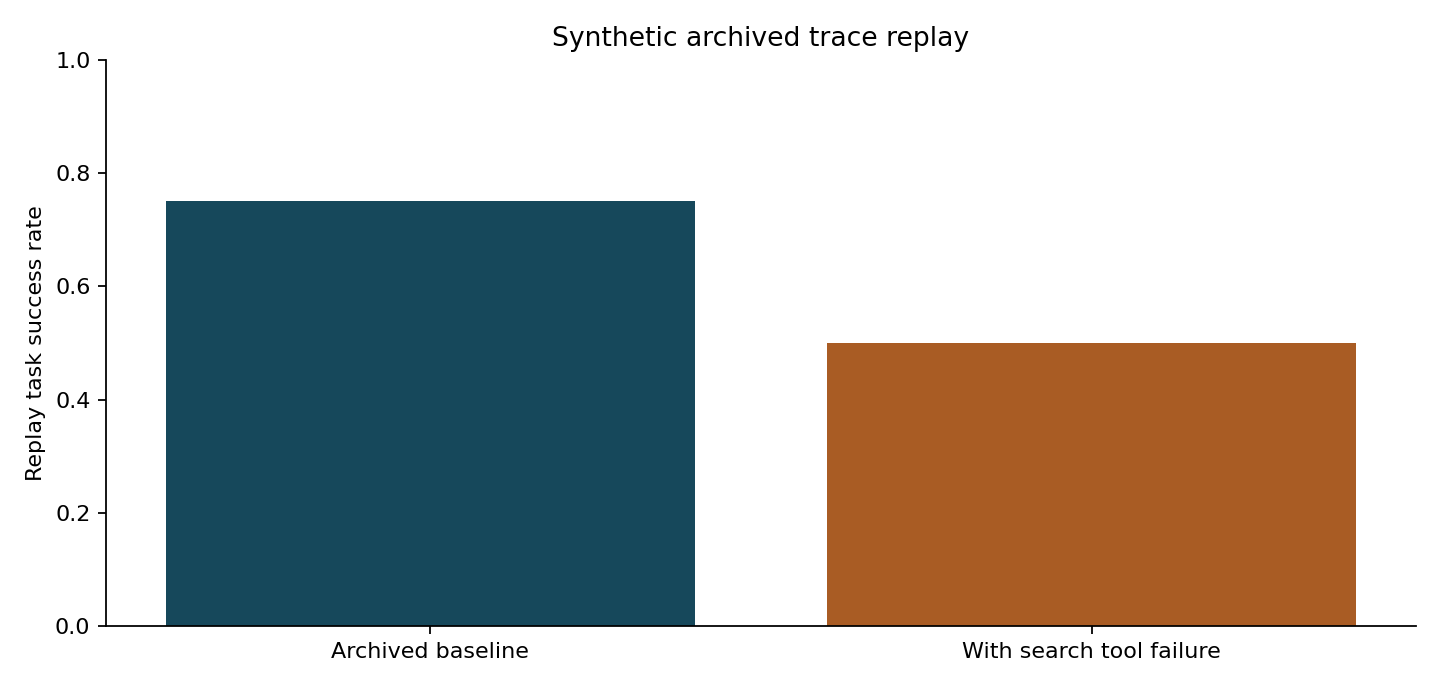

In [4]:
report=json.loads((BASE/"outputs/evaluation.json").read_text())
print("Passed",report["passed"],"of",report["cases"],"fixture tasks")
print("Tool failure rate",report["tool_failure_rate"],"| Mean latency (ms)",report["mean_latency_ms"],"| Hosted model spend ($)",report["total_model_api_cost_usd"])
display(Image(filename=str(BASE/"outputs/overview.png")))